# COMET — GRN dictionary + ATAC-led velocity (cleaned)

Unpaired scRNA + scATAC → per-cell GRN mixing + differentiation velocity.

**What changed vs. the previous version**
- All paths / run tags are set once in **Config** below.
- GRN mixing no longer collapses to hard assignment: archetype (not centroid) init, a
  shared-base + residual-atom reconstruction, and a geometry-derived soft-target prior
  (replaces the entropy/Dirichlet knobs). Temperature is fixed at 1.0 everywhere,
  including evaluation/saving (the old code sharpened to 0.1, which *displayed* hard
  assignment even when weights were soft).
- Velocity direction now comes from the **ATAC→RNA lead** propagated through the learned
  GRN, not from `steady(RNA) − RNA` (which is ~0 at a self-consistent fixed point and
  points inward at the origin). No pseudotime is used in the velocity.
- One arrow plot only (scVelo-style stream), fed by a drift-corrected projection.

---

## Config — set everything here


In [5]:
import os

# ── file system ───────────────────────────────────────────────────────────────
BASE     = "/home/sc5625/cll_project/decipher_atac_project/decipher-atac/paired"
RUN_TAG  = "paired_run_original"                       # change per run
OUT_DIR  = f"bert_grn_out_{RUN_TAG}"
os.makedirs(OUT_DIR, exist_ok=True)

# ── input files (paired dataset) ──────────────────────────────────────────────
RNA_H5AD      = f"{BASE}/Ma-2020-RNA.h5ad"
ATAC_H5AD     = f"{BASE}/Ma-2020-ATAC.h5ad"            # SAME cells as RNA (paired)
PEAK_TF_MTX   = f"{BASE}/ma2020_peak_tf.mtx"           # (n_peaks x n_tf); rows align to ATAC var
TF_NAMES_TXT  = f"{BASE}/ma2020_tf_names.txt"          # columns of PEAK_TF_MTX
PEAK_GENE_CSV = f"{BASE}/ma2020_peak_gene.csv"         # tab-sep: peak <tab> gene
DECIPHER_DIR  = f"{BASE}/paired_decipher_outputs"      # holds the decipher embeddings .npz
# optional external comparison file (only used by the CellOracle appendix)
CELLORACLE_A  = f"{BASE}/models/bert_grn_out/A_learned.npy"

# ── column names / keys ───────────────────────────────────────────────────────
PSEUDOTIME_KEY = "facs_pseudotime"        # obs column, used ONLY for plot coloring
DECIPHER_BASIS = "X_decipher"             # for the scanpy marker-gene panel

# ── model / data hyperparameters ──────────────────────────────────────────────
N_TOP_HVG   = 3000
D_ATOMS     = 4        # number of GRN dictionary atoms (archetypes)
NUM_RUNS    = 1
N_EPOCHS    = 120
PHASE1_EPOCHS = 40
BATCH_SIZE  = 512
NEIGHBOR_SPACE = "decipher"               # "decipher" | "pca" | "latent"
CELLTYPE_KEY = "cell_type"

# GRN-mixing controls
GEO_TAU_SCALE = 0.5     # smaller -> sharper geometric targets q (less mixing)
LAMBDA_GRN    = 1.0     # weight of GRN-propagated lead inside the velocity disequilibrium

MARKER_GENES = ['CD34', 'MPO', 'LYZ', 'GATA1', 'SPI1', 'CEBPA']

# hair lineage restriction + stratified subsampling
HAIR_LINEAGE = [
    "ahigh CD34+ bulge",
    "alow CD34+ bulge",
    "ORS",
    "TAC-1",
    "TAC-2",
    "IRS",
    "Hair Shaft-Cuticle/Cortex",
    "Medulla",
]
N_CELLS_SUBSET = 5000
RANDOM_SEED    = 0

## Imports


In [7]:
import json
import numpy as np
import pandas as pd
import scipy.io
import anndata as ad
import scanpy as sc
from scipy.sparse import lil_matrix, issparse
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.decomposition import PCA, NMF
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, MiniBatchKMeans

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, RandomSampler

import matplotlib.pyplot as plt
import os, glob


## Helper functions


In [9]:
def as_dense(x):
    return x.toarray() if issparse(x) else np.asarray(x)

def jaccard(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    denom = np.logical_or(a, b).sum()
    return 0.0 if denom == 0 else np.logical_and(a, b).sum() / denom

def top_support_mask(vec, frac=0.05):
    vec = np.abs(np.asarray(vec).ravel())
    k = max(1, int(np.ceil(frac * vec.size)))
    mask = np.zeros(vec.size, dtype=bool)
    mask[np.argpartition(vec, -k)[-k:]] = True
    return mask

def zscore_cols(A, eps=1e-8):
    """Per-gene (per-column) z-score across cells."""
    A = np.asarray(A, dtype=np.float32)
    return (A - A.mean(axis=0, keepdims=True)) / (A.std(axis=0, keepdims=True) + eps)

def norm_name(s):
    """Case/space-insensitive key so mouse symbols match across files."""
    return str(s).strip().casefold()


## Step 1: Load RNA, normalize, select HVGs, define universe


In [10]:
def load_decipher(decipher_dir):
    """Load z (latent) + v (2D) from an .npz in the decipher outputs dir."""
    cands = sorted(glob.glob(os.path.join(decipher_dir, "*.npz")))
    assert cands, f"No .npz found in {decipher_dir}"
    for path in cands:
        d = np.load(path, allow_pickle=True)
        keys = list(d.keys())
        z = next((d[k] for k in ('z', 'decipher_z', 'Z', 'z_latent', 'X_decipher_z') if k in keys), None)
        v = next((d[k] for k in ('v', 'decipher_v', 'V', 'z_2d', 'X_decipher') if k in keys), None)
        if z is None or v is None:                      
            arrs = [(k, d[k]) for k in keys if getattr(d[k], 'ndim', 0) == 2]
            v = v if v is not None else next((a for _, a in arrs if a.shape[1] == 2), None)
            z = z if z is not None else next((a for _, a in arrs if a.shape[1] > 2), None)
        if z is not None and v is not None:
            print(f"Loaded Decipher from {os.path.basename(path)} (keys={keys})")
            return np.asarray(z, np.float32), np.asarray(v, np.float32)
    raise KeyError(f"Could not find z/v arrays in {cands}")

# ── load both modalities (paired: identical cells, identical order) ───────────
rna_adata  = ad.read_h5ad(RNA_H5AD)
atac_adata = ad.read_h5ad(ATAC_H5AD)

# enforce the pairing explicitly; reorder ATAC to RNA if needed
assert rna_adata.n_obs == atac_adata.n_obs, "RNA/ATAC cell counts differ — not paired?"
if not (rna_adata.obs_names == atac_adata.obs_names).all():
    atac_adata = atac_adata[rna_adata.obs_names].copy()
assert (rna_adata.obs_names == atac_adata.obs_names).all(), "cell order still mismatched"
print(f"Paired cells: {rna_adata.n_obs} | RNA genes: {rna_adata.n_vars} | ATAC peaks: {atac_adata.n_vars}")

# ── restrict to hair-lineage cell types (same mask applied to both modalities) ─
mask = rna_adata.obs[CELLTYPE_KEY].isin(HAIR_LINEAGE)
rna_adata  = rna_adata[mask].copy()
atac_adata = atac_adata[mask].copy()
assert (rna_adata.obs_names == atac_adata.obs_names).all(), "cell order mismatched after lineage filter"
print(f"Hair-lineage cells: {rna_adata.n_obs}")

# =========================================================================
# NEW: Load Decipher HERE, while rna_adata still has 11,659 cells
# =========================================================================
Z_dec_full, V_dec2_full = load_decipher(DECIPHER_DIR)
assert Z_dec_full.shape[0] == rna_adata.n_obs, \
    f"Decipher array rows ({Z_dec_full.shape[0]}) != filtered cells ({rna_adata.n_obs})"

# ── stratified subsample to N_CELLS_SUBSET, proportional per cell type ────────
rng = np.random.default_rng(RANDOM_SEED)
if rna_adata.n_obs > N_CELLS_SUBSET:
    obs_df = rna_adata.obs[[CELLTYPE_KEY]].copy()
    obs_df["orig_idx"] = np.arange(rna_adata.n_obs)
    frac = N_CELLS_SUBSET / rna_adata.n_obs

    keep_idx = []
    for ct, grp in obs_df.groupby(CELLTYPE_KEY):
        n_keep = min(len(grp), max(1, int(round(len(grp) * frac))))
        chosen = rng.choice(grp["orig_idx"].values, size=n_keep, replace=False)
        keep_idx.append(chosen)
    keep_idx = np.sort(np.concatenate(keep_idx))

    # Apply the EXACT SAME mask to RNA, ATAC, and the Decipher arrays
    rna_adata  = rna_adata[keep_idx].copy()
    atac_adata = atac_adata[keep_idx].copy()
    Z_dec      = Z_dec_full[keep_idx].copy()
    V_dec2     = V_dec2_full[keep_idx].copy()
    
    assert (rna_adata.obs_names == atac_adata.obs_names).all(), "cell order mismatched after subsample"
    print(f"Subsampled to: {rna_adata.n_obs} cells")
else:
    Z_dec  = Z_dec_full
    V_dec2 = V_dec2_full

# Assign it securely to the now-subsampled rna_adata
rna_adata.obsm[DECIPHER_BASIS] = V_dec2

# ── RNA normalization (X is raw counts) ───────────────────────────────────────
print("Normalizing and log-transforming RNA counts...")
# ... [rest of your original normalization code continues here unchanged]
sc.pp.normalize_total(rna_adata, target_sum=1e4)
sc.pp.log1p(rna_adata)

sc.pp.highly_variable_genes(rna_adata, n_top_genes=N_TOP_HVG, subset=False)
hvg_genes = set(rna_adata.var_names[rna_adata.var['highly_variable']])

gene_names_all   = np.array(rna_adata.var_names.astype(str))
gene_to_idx_full = {g: i for i, g in enumerate(gene_names_all)}
# normalized-key -> canonical RNA symbol (first occurrence wins)
rna_norm_to_canon = {}
for g in gene_names_all:
    rna_norm_to_canon.setdefault(norm_name(g), g)
X_full = as_dense(rna_adata.X).astype(np.float32)

# ── context files ─────────────────────────────────────────────────────────────
peak_tf = scipy.io.mmread(PEAK_TF_MTX).tocsr()                      # (P, T_all)
motif_tf_names   = open(TF_NAMES_TXT).read().split()                # length T_all
motif_norm_to_col = {}
for i, t in enumerate(motif_tf_names):
    motif_norm_to_col.setdefault(norm_name(t), i)

peak_gene = pd.read_csv(PEAK_GENE_CSV, sep="\t")
peak_gene.columns = [c.strip().lower() for c in peak_gene.columns]  # -> 'peak','gene'
pg_gene_norm = peak_gene["gene"].astype(str).map(norm_name)
genes_in_peaks_norm = set(pg_gene_norm.unique())

# ── functional TFs = motif TFs that are present as RNA genes (canonical names) ─
A_tfs = list(dict.fromkeys(
    rna_norm_to_canon[norm_name(t)] for t in motif_tf_names if norm_name(t) in rna_norm_to_canon
))
A_tfs = np.array(A_tfs, dtype=str)

# ── target genes = (in peaks AND HVG) OR functional TF; TFs always protected ──
A_tf_set = set(A_tfs)
A_genes = np.array([
    g for g in gene_names_all
    if (norm_name(g) in genes_in_peaks_norm and g in hvg_genes) or g in A_tf_set
], dtype=str)
print(f"Target genes (A_genes): {len(A_genes)}  |  TFs (A_tfs): {len(A_tfs)}")

gene_idx = np.array([gene_to_idx_full[g] for g in A_genes], dtype=int)
tf_idx   = np.array([gene_to_idx_full[t] for t in A_tfs],   dtype=int)
X    = X_full[:, gene_idx]     # (N, G) normalized HVG expression
X_TF = X_full[:, tf_idx]       # (N, T) normalized TF expression
sub_g2i = {g: i for i, g in enumerate(A_genes)}

Paired cells: 32231 | RNA genes: 21478 | ATAC peaks: 340341
Hair-lineage cells: 11659
Loaded Decipher from decipher_embeddings.npz (keys=['v', 'z'])


/tmp/ipykernel_20879/2398175729.py:52: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for ct, grp in obs_df.groupby(CELLTYPE_KEY):


Subsampled to: 4999 cells
Normalizing and log-transforming RNA counts...
Target genes (A_genes): 2719  |  TFs (A_tfs): 788


## Step 2: Build M (gene × TF motif-accessibility mask)


In [11]:
# ── canonical peak names in ATAC-var order (peak_tf rows assumed to match ATAC var) ──
av = atac_adata.var
if {'chrom', 'chromStart', 'chromEnd'}.issubset(av.columns):
    peak_names = (av['chrom'].astype(str) + "_" +
                  av['chromStart'].astype(int).astype(str) + "_" +
                  av['chromEnd'].astype(int).astype(str)).tolist()
else:
    peak_names = list(atac_adata.var_names.astype(str))

# if the constructed names don't overlap peak_gene, fall back to raw var_names
_pg_peaks = set(peak_gene["peak"].astype(str))
if len(set(peak_names) & _pg_peaks) < 0.2 * len(_pg_peaks):
    peak_names = list(atac_adata.var_names.astype(str))
peak_to_idx = {p: i for i, p in enumerate(peak_names)}
print(f"Peaks: {len(peak_names)} | overlap with peak_gene: "
      f"{len(set(peak_names) & _pg_peaks)}/{len(_pg_peaks)}")
assert peak_tf.shape[0] == len(peak_names), \
    f"peak_tf rows ({peak_tf.shape[0]}) != n_peaks ({len(peak_names)}); check row ordering"

# ── peak × gene incidence (rows = ATAC-var order, cols = A_genes) ─────────────
P, G = len(peak_names), len(A_genes)
peak_gene_mat = lil_matrix((P, G), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = str(row["peak"]); gk = norm_name(row["gene"])
    if p in peak_to_idx and gk in rna_norm_to_canon:
        g = rna_norm_to_canon[gk]
        if g in sub_g2i:
            peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1.0
peak_gene_mat = peak_gene_mat.tocsr()

# gene × TF mask
M_full = (peak_gene_mat.T @ peak_tf)              # (G, T_all)
M_full = (M_full > 0).astype(np.float32)
tf_col = np.array([motif_norm_to_col[norm_name(t)] for t in A_tfs], dtype=int)
M = M_full[:, tf_col].toarray().astype(np.float32)
assert M.shape == (len(A_genes), len(A_tfs))
print(f"M nonzero density: {M.mean():.4f}")

Peaks: 340341 | overlap with peak_gene: 31114/31114
M nonzero density: 0.2306


## Step 3: ATAC gene activity + population accessibility prior


In [12]:
atac_X = atac_adata.X.astype(np.float32)          # (N, P) cells x peaks, RNA-aligned order
if not issparse(atac_X):
    atac_X = csr_matrix(atac_X)

gene_activity = atac_X @ peak_gene_mat            # (N, G) sparse — per-cell, no matching
gene_activity = normalize(gene_activity, norm="l1", axis=1)
gene_activity = np.log1p(as_dense(gene_activity)).astype(np.float32)
print(f"gene_activity: {gene_activity.shape} (paired, per-cell)")

# population accessibility per gene, [0,1] — used by the ATAC direction penalty
gene_access   = gene_activity.mean(axis=0)
gene_access   = (gene_access - gene_access.min()) / (gene_access.max() - gene_access.min() + 1e-8)
gene_access_t = torch.tensor(gene_access, dtype=torch.float32)

gene_activity: (4999, 2719) (paired, per-cell)


## Step 4: TF accessibility prior


In [13]:
def build_tf_access_prior(gene_activity, A_tfs, sub_g2i):
    T = len(A_tfs)
    tf_access = np.zeros(T, dtype=np.float32)
    for i, tf in enumerate(A_tfs):
        if tf in sub_g2i:
            tf_access[i] = float(gene_activity[:, sub_g2i[tf]].mean())
    lo, hi = tf_access.min(), tf_access.max()
    return (tf_access - lo) / (hi - lo + 1e-8)

TF_access_prior = build_tf_access_prior(gene_activity, A_tfs, sub_g2i)
TF_access_t = torch.tensor(TF_access_prior, dtype=torch.float32)
print(f"TF access prior: mean={TF_access_prior.mean():.3f}  "
      f"nonzero={np.mean(TF_access_prior > 0.05):.1%}")

TF access prior: mean=0.167  nonzero=59.3%


## Step 5: Load Decipher embedding


In [15]:
# pseudotime — COLORING / read-only diagnostics ONLY, never used by the model.
def build_pseudotime_proxy(rna_adata, Z_dec, V_dec2, key):
    if key is not None and key in rna_adata.obs:
        pt = rna_adata.obs[key].astype(np.float32).values
    else:
        try:                                            # decipher-latent diffusion pseudotime
            a = rna_adata.copy(); a.obsm['X_dec'] = Z_dec
            sc.pp.neighbors(a, use_rep='X_dec', n_neighbors=15)
            a.uns['iroot'] = int(np.argmax(Z_dec[:, 0]))
            sc.tl.diffmap(a); sc.tl.dpt(a)
            pt = a.obs['dpt_pseudotime'].astype(np.float32).values
            pt[~np.isfinite(pt)] = np.nanmedian(pt[np.isfinite(pt)])
        except Exception as e:                          # robust fallback: 1st decipher-viz axis
            print(f"DPT proxy failed ({e}); using Decipher axis rank.")
            pt = V_dec2[:, 0].astype(np.float32)
    return (pt - pt.min()) / (np.ptp(pt) + 1e-8)

cell_types = rna_adata.obs['cell_type']

pseudo_norm = build_pseudotime_proxy(rna_adata, Z_dec, V_dec2, PSEUDOTIME_KEY)
print(f"X {rna_adata.X.shape} | Z_dec {Z_dec.shape} | V_dec2 {V_dec2.shape}")
print(f"cell types: {pd.Series(cell_types).value_counts().to_dict()}")

X (4999, 21478) | Z_dec (4999, 10) | V_dec2 (4999, 2)
cell types: {'TAC-1': 1445, 'alow CD34+ bulge': 805, 'ahigh CD34+ bulge': 667, 'Hair Shaft-Cuticle/Cortex': 500, 'ORS': 441, 'TAC-2': 432, 'Medulla': 421, 'IRS': 288}


## Step 6: Archetypes + geometry-derived soft mixing targets

The single most important change for GRN mixing. Instead of KMeans **centroids** (every
cell is nearest one centroid → hard assignment is optimal), we pick D **archetypes** =
extreme points of the manifold (branch tips + origin) via furthest-point sampling, then
define each cell's target mixing `q_i` as its softmax proximity to those archetypes.
Interior/transition cells get genuinely mixed `q`; committed tips get sharp `q`. This
is topology-agnostic (branching → tips+origin, linear → two ends, etc.).


In [16]:
def select_archetypes_fps(Z, D, seed=0):
    """Furthest-point sampling → indices of D extreme cells (manifold corners)."""
    rng = np.random.default_rng(seed)
    c   = Z.mean(axis=0)
    first = int(np.argmax(((Z - c) ** 2).sum(1)))
    idx = [first]
    dmin = ((Z - Z[first]) ** 2).sum(1)
    for _ in range(D - 1):
        nxt = int(np.argmax(dmin))
        idx.append(nxt)
        dmin = np.minimum(dmin, ((Z - Z[nxt]) ** 2).sum(1))
    return np.array(idx, dtype=int)

def geometric_soft_targets(Z, arch_idx, tau_scale=0.5):
    """q_i = softmax(-||z_i - z_arch||^2 / tau). Returns (N, D), rows sum to 1."""
    A = Z[arch_idx]                                    # (D, latent)
    d2 = ((Z[:, None, :] - A[None, :, :]) ** 2).sum(-1)  # (N, D)
    tau = np.median(d2) * tau_scale + 1e-8
    q = np.exp(-d2 / tau)
    q = q / (q.sum(1, keepdims=True) + 1e-8)
    return q.astype(np.float32)

arch_idx = select_archetypes_fps(Z_dec, D_ATOMS, seed=0)
q_target = geometric_soft_targets(Z_dec, arch_idx, tau_scale=GEO_TAU_SCALE)

_ent = -(q_target * np.log(q_target + 1e-8)).sum(1).mean()
print(f"Archetype cells: {arch_idx.tolist()}")
print(f"Soft-target entropy: {_ent:.3f} / {np.log(D_ATOMS):.3f} max "
      f"(want clearly between 0 and max)")

Archetype cells: [2083, 3401, 4294, 4642]
Soft-target entropy: 0.905 / 1.386 max (want clearly between 0 and max)


## Step 7: GRN dictionary model (shared base + residual atoms)

`predict_rna = A_base @ tf + Σ_d w_d (A_d @ tf)`. The shared base carries the common
regulatory program so the atoms only encode lineage-specific *residuals*. This removes
most of the reconstruction incentive to hard-assign — the crux that lets soft mixing
survive the likelihood term. The same effective per-cell GRN is reused by the velocity.


In [17]:
def init_atoms_from_soft_targets(X, q, M, A_tfs):
    """Soft-LFC init: each atom's weights come from cells weighted toward its archetype."""
    D = q.shape[1]
    G = X.shape[1]
    W_init = np.zeros((D, G, len(A_tfs)), dtype=np.float32)
    for d in range(D):
        w = q[:, d]                                   # (N,) soft membership
        wsum = w.sum() + 1e-8
        mean_in  = (X * w[:, None]).sum(0) / wsum
        mean_out = (X * (1 - w)[:, None]).sum(0) / ((1 - w).sum() + 1e-8)
        lfc = np.log1p(mean_in) - np.log1p(mean_out)  # (G,)
        for t_i in range(len(A_tfs)):
            col = M[:, t_i]
            if col.sum() == 0:
                continue
            lfc_masked = lfc * col
            rng = np.abs(lfc_masked).max() + 1e-8
            W_init[d, :, t_i] = lfc_masked / rng * 0.3
    return W_init


class GRNDictionary(nn.Module):
    def __init__(self, G, T, M, D=4):
        super().__init__()
        self.D, self.G, self.T = D, G, T
        self.W_raw  = nn.Parameter(torch.zeros(D, G, T))   # residual atoms
        self.W_base = nn.Parameter(torch.zeros(G, T))      # shared base
        self.register_buffer("M", torch.tensor(M, dtype=torch.float32))
        self.register_buffer("TF_access", torch.zeros(T))
        self.register_buffer("mean_tf",  torch.zeros(T))

    def init_from_atoms(self, W_init):
        with torch.no_grad():
            self.W_raw.copy_(torch.tensor(np.arctanh(np.clip(W_init, -0.95, 0.95)),
                                          dtype=torch.float32))
        print("GRN atoms initialized from archetype soft-LFC profiles (base starts at 0).")

    @property
    def A_dict(self):
        return torch.tanh(self.W_raw) * self.M.unsqueeze(0)   # (D, G, T)

    @property
    def A_base(self):
        return torch.tanh(self.W_base) * self.M               # (G, T)

    def _atom_term(self, X_in, weights):
        # sum_d w_d (X_in @ A_d.T) without materializing (B,G,T)
        P = torch.einsum('bt,dgt->dbg', X_in, self.A_dict)    # (D, B, G)
        return (P * weights.T.unsqueeze(-1)).sum(0)           # (B, G)

    def predict_rna(self, X_TF, weights):
        """Steady-state RNA prediction from TF expression (base + residual atoms)."""
        return (X_TF @ self.A_base.T) + self._atom_term(X_TF, weights)

    def production_from_lead(self, tf_lead, weights):
        """Effective per-cell GRN applied to the ATAC->RNA TF lead (for velocity)."""
        return (tf_lead @ self.A_base.T) + self._atom_term(tf_lead, weights)

    def effective_A(self, weights_vec):
        """weights_vec: (D,) -> (G, T) effective GRN including base."""
        return self.A_base + torch.einsum('d,dgt->gt', weights_vec, self.A_dict)

    def sparsity_loss(self):
        return torch.abs(self.A_dict).mean() + torch.abs(self.A_base).mean()

    def diversity_loss(self):
        """Keep residual atoms distinct in parameter AND prediction space."""
        A_flat = self.A_dict.reshape(self.D, -1)
        A_norm = F.normalize(A_flat, dim=1)
        eye = torch.eye(self.D, device=A_flat.device)
        param_div = ((A_norm @ A_norm.T) * (1 - eye)).abs().mean()

        pred = torch.einsum('dgt,t->dg', self.A_dict, self.mean_tf)
        pred = F.normalize(pred, dim=1)
        pred_div = ((pred @ pred.T) * (1 - eye)).abs().mean()
        return 0.5 * param_div + 0.5 * pred_div

    def tf_access_consistency_loss(self):
        closed = 1.0 - self.TF_access.clamp(0, 1)
        return (torch.abs(self.A_dict) * closed.unsqueeze(0).unsqueeze(0)).mean()


class CellStateEncoder(nn.Module):
    """RNA -> D mixing weights. Warm-started to reproduce the soft targets q (not hard labels)."""
    def __init__(self, G, D, hidden=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(G, hidden), nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, hidden // 2), nn.GELU(),
        )
        self.head = nn.Linear(hidden // 2, D)
        self.D = D

    def init_from_soft_targets(self, X, q, n_epochs=40, lr=1e-3, batch=256):
        """Distill the geometric soft targets q into the encoder (KL, not cross-entropy)."""
        print("Pre-training encoder to match geometric soft targets...")
        self.train()
        opt = torch.optim.Adam(self.parameters(), lr=lr)
        X_t = torch.tensor(X, dtype=torch.float32)
        q_t = torch.tensor(q, dtype=torch.float32)
        dl  = DataLoader(TensorDataset(X_t, q_t), batch_size=batch, shuffle=True)
        for ep in range(n_epochs):
            tot = 0.0
            for xb, qb in dl:
                logp = F.log_softmax(self.head(self.encoder(xb)), dim=-1)
                loss = (qb * (torch.log(qb + 1e-8) - logp)).sum(1).mean()   # KL(q||p)
                opt.zero_grad(); loss.backward(); opt.step()
                tot += loss.item()
            if ep % 10 == 0:
                print(f"  encoder pretrain epoch {ep}: KL={tot/len(dl):.4f}")
        print("Encoder pretraining complete.")

    def forward(self, rna, temperature=1.0):
        logits = self.head(self.encoder(rna))
        return F.softmax(logits / temperature, dim=-1)

## Step 8: Linear decoder (interpretable 2D embedding)


In [18]:
class LinearDecoder(nn.Module):
    def __init__(self, hidden, G, ld_dim=2):
        super().__init__()
        self.bottleneck = nn.Linear(hidden, ld_dim)
        self.W_dec = nn.Linear(ld_dim, G, bias=True)
        nn.init.normal_(self.W_dec.weight, std=0.01); nn.init.zeros_(self.W_dec.bias)
        nn.init.orthogonal_(self.bottleneck.weight);  nn.init.zeros_(self.bottleneck.bias)

    def forward(self, h):
        z = self.bottleneck(h)
        return z, self.W_dec(z)

    def reconstruction_loss(self, h, x):
        _, xh = self.forward(h)
        return F.mse_loss(xh, x)

    def ld_regularization_loss(self, h):
        z, _ = self.forward(h)
        zc = z - z.mean(0)
        var_loss = -torch.log((zc ** 2).mean(0) + 1e-4).mean()
        cov = (zc.T @ zc) / zc.shape[0]
        orth_loss = cov[0, 1].pow(2) + cov[1, 0].pow(2)
        return var_loss + orth_loss

    def get_gene_loadings(self):
        return self.W_dec.weight.detach().cpu().numpy()   # (G, 2)


def plot_ld_embedding(z_2d_rna, pseudo_norm, gene_loadings, A_genes,
                      z_2d_atac=None, highlight_genes=None, n_arrow_genes=15, save_path=None):
    has_atac = z_2d_atac is not None
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=150)

    ax = axes[0]
    if has_atac:
        ax.scatter(z_2d_atac[:, 0], z_2d_atac[:, 1], c='lightgray', s=6, alpha=0.4,
                   edgecolors='none', label='ATAC', rasterized=True)
    scv = ax.scatter(z_2d_rna[:, 0], z_2d_rna[:, 1], c=pseudo_norm, cmap='viridis',
                     s=10, alpha=0.7, edgecolors='none', rasterized=True)
    plt.colorbar(scv, ax=ax, fraction=0.04, label='Pseudotime')
    ax.set_title('LD-VAE (RNA by pseudotime)', fontsize=10)
    ax.set_xlabel('LD 1'); ax.set_ylabel('LD 2')

    ax = axes[1]
    ax.scatter(z_2d_rna[:, 0], z_2d_rna[:, 1], c='#2166ac', s=8, alpha=0.6,
               edgecolors='none', label=f'RNA (n={len(z_2d_rna)})', rasterized=True)
    if has_atac:
        ax.scatter(z_2d_atac[:, 0], z_2d_atac[:, 1], c='#d73027', s=8, alpha=0.6,
                   edgecolors='none', label=f'ATAC (n={len(z_2d_atac)})', rasterized=True)
    ax.set_title('LD-VAE (by modality)', fontsize=10); ax.legend(fontsize=8, frameon=False)
    ax.set_xlabel('LD 1'); ax.set_ylabel('LD 2')

    ax = axes[2]
    ax.scatter(z_2d_rna[:, 0], z_2d_rna[:, 1], c='lightgray', s=4, alpha=0.3,
               edgecolors='none', rasterized=True)
    mags = np.linalg.norm(gene_loadings, axis=1)
    if highlight_genes is not None:
        hi = [i for i, g in enumerate(A_genes) if g in highlight_genes]
        other = [i for i in np.argsort(-mags) if i not in hi]
        show = hi + other[:max(0, n_arrow_genes - len(hi))]
    else:
        show = np.argsort(-mags)[:n_arrow_genes]
    xr = z_2d_rna[:, 0].ptp(); yr = z_2d_rna[:, 1].ptp()
    scale = 0.35 * min(xr, yr) / (mags[show].max() + 1e-8)
    for idx in show:
        dx, dy = gene_loadings[idx] * scale
        col = '#d73027' if (highlight_genes and A_genes[idx] in highlight_genes) else '#2166ac'
        ax.annotate('', xy=(dx, dy), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color=col, lw=1.5))
        ax.text(dx * 1.08, dy * 1.08, A_genes[idx], fontsize=7, color=col, ha='center', va='center')
    ax.set_title('Gene loadings biplot', fontsize=10)
    ax.set_xlabel('LD 1'); ax.set_ylabel('LD 2')

    for a in axes:
        a.spines['top'].set_visible(False); a.spines['right'].set_visible(False)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=150)
    plt.show()

## Step 9: BERT-style masked reconstruction (drives GRN learning)


In [19]:
def masked_reconstruction_loss(grn, mix_weights, rna_batch, tf_batch,
                               tf_indices_in_G, mask_frac=0.40):
    B, Gg = rna_batch.shape
    device = rna_batch.device
    mask = torch.rand(B, Gg, device=device) < mask_frac

    tf_input_masked = tf_batch.clone()
    batch_idx = torch.arange(B, device=device).unsqueeze(1)
    tf_input_masked[batch_idx, torch.arange(len(tf_indices_in_G), device=device)] *= \
        (~mask[batch_idx, tf_indices_in_G]).float()

    rna_pred = grn.predict_rna(tf_input_masked, mix_weights)
    if mask.sum() == 0:
        return rna_pred.mean() * 0.0
    return F.mse_loss(rna_pred[mask], rna_batch[mask])


# local index of each TF inside A_genes (run once)
tf_indices_in_G = torch.tensor(
    [sub_g2i.get(tf, -1) for tf in A_tfs], dtype=torch.long
)
assert (tf_indices_in_G >= 0).all(), "some TF not found in A_genes"

## Step 10: Velocity head (ATAC→RNA lead, not RNA→RNA residual)

The head learns a calibrated (degradation/kinetics) transform of the disequilibrium.
The disequilibrium itself is built in the training loop from the chromatin lead + the
GRN-propagated lead — that is where the arrow of time enters.


In [20]:
class DictVelocityHead(nn.Module):
    def __init__(self, G, hidden=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(G, hidden), nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden), nn.GELU(),
            nn.Linear(hidden, G),
        )
        self.scale = nn.Parameter(torch.ones(1) * 0.1)

    def forward(self, rna, disequil):
        return self.net(disequil) * self.scale


def velocity_consistency_loss(velocity, disequil):
    """Align displacement with the chromatin-led disequilibrium; guard magnitude."""
    v = F.normalize(velocity, dim=1)
    d = F.normalize(disequil, dim=1)
    cos = (v * d).sum(1)
    mag = torch.abs(velocity.norm(dim=1) - disequil.norm(dim=1).detach()).mean()
    return (1.0 - cos).mean() + 0.1 * mag


def atac_direction_loss(velocity, gene_access_batch):
    """A closed locus should not be pushed up (consistency guard, cheap and harmless)."""
    closed = 1.0 - gene_access_batch.to(velocity.device)
    return (closed * torch.relu(velocity)).mean()


# NOTE: velocity_smoothness_loss has been REMOVED.
#
# It pulled each cell's displacement toward the flat MEAN of its neighbors'
# displacement — a reasonable idea in a locally-unimodal, noisy region, but the
# wrong idea at a real branch point: if a cell's spatial neighbors are already
# committed to different downstream fates, their individual displacement vectors
# point in genuinely different directions, and a flat mean of divergent vectors
# collapses toward zero (or an arbitrary residual) instead of preserving either
# fate. Because this was a training-time loss (not just a visualization
# convenience), it was actively teaching the network to erase real fan-out at
# the hub, which is the swirling/converging pattern you're seeing there.
#
# Denoising now happens exactly once, upstream, on the ATAC input itself
# (Step 11) — a per-gene *scalar* can be safely neighbor-averaged without
# canceling directional information, because it isn't a direction.

## Step 11: Neighbor index + local ATAC estimate


In [21]:
def build_neighbor_index(X, V_dec2, Z_dec, mode="latent", k=15):
    if mode == "decipher":
        ref = V_dec2
    elif mode == "pca":
        ref = PCA(n_components=min(50, X.shape[1] - 1), random_state=42).fit_transform(X)
    elif mode == "latent":
        ref = Z_dec
    else:
        raise ValueError(mode)
    nbrs = NearestNeighbors(n_neighbors=k).fit(ref)
    _, ni = nbrs.kneighbors(ref)
    return torch.tensor(ni, dtype=torch.long)


def build_local_atac(X_rna, gene_activity, cluster_space, n_clusters=40, k_atac=8, seed=42):
    """Per-cell ATAC accessibility via pseudo-bulk cluster matching (unpaired-safe).

    cluster_space should be a space that actually resolves cell state well — pass
    the Decipher LATENT (Z_dec), not the 2D viz coordinates. Clustering in 2D
    viz space throws away most of the resolution the model has learned and was
    the main source of blocky, noisy per-cell ATAC estimates near the hub, which
    is where the directional noise in the displacement field was coming from.
    """
    G = X_rna.shape[1]
    km = MiniBatchKMeans(n_clusters=n_clusters, random_state=seed, n_init=5)
    labels = km.fit_predict(cluster_space)
    cluster_rna = np.zeros((n_clusters, G), dtype=np.float32)
    for c in range(n_clusters):
        m = labels == c
        if m.sum():
            cluster_rna[c] = X_rna[m].mean(0)
    cr = normalize(cluster_rna, norm='l2'); ga = normalize(gene_activity, norm='l2')
    _, aidx = NearestNeighbors(n_neighbors=k_atac).fit(ga).kneighbors(cr)
    cluster_access = np.stack([gene_activity[aidx[c]].mean(0) for c in range(n_clusters)])
    local = cluster_access[labels]
    lo = local.min(0, keepdims=True); hi = local.max(0, keepdims=True)
    return ((local - lo) / (hi - lo + 1e-8)).astype(np.float32)


def knn_smooth(signal, neighbor_idx, k=10):
    """Average a per-cell, per-gene SCALAR signal over its k nearest latent-space
    neighbors. This is now the only denoising step in the pipeline. It's safe to
    apply to a scalar accessibility feature because there's no direction to
    cancel — unlike smoothing a displacement vector, this can only reduce noise,
    never erase a bifurcation.
    """
    nb = neighbor_idx[:, :k]
    return signal[nb].mean(axis=1)


# NEIGHBOR_SPACE now defaults to "latent" — this is the fix, not a stylistic choice.
NEIGHBOR_SPACE = "latent"

# decipher_data = np.load(DECIPHER_NPZ)   # if not already loaded earlier in your pipeline
# Z_dec  = decipher_data["z"].astype(np.float32)   # (N, 10) latent space
# V_dec2 = decipher_data["v"].astype(np.float32)   # (N, 2)  vis space

neighbor_indices_t = build_neighbor_index(X, V_dec2, Z_dec, mode=NEIGHBOR_SPACE, k=15)

# Cluster in the LATENT space (Z_dec), not the 2D viz space — this alone removes
# a lot of the blockiness in local_access.
local_access = build_local_atac(X, gene_activity, Z_dec, n_clusters=40, k_atac=8)

# Denoise the raw per-cell ATAC estimate over its latent-space neighborhood.
# This replaces the old displacement-vector smoothing loss as the pipeline's
# single denoising step, moved from output to input.
local_access = knn_smooth(local_access, neighbor_indices_t.numpy(), k=10)

# ── shared, per-gene z-scored lead signals (computed once) ────────────────────
# atac_z - rna_z is the ATAC->RNA lead: open-but-quiet genes are primed to rise.
atac_z = zscore_cols(local_access)     # (N, G)
rna_z  = zscore_cols(X)                # (N, G)
atac_z_t = torch.tensor(atac_z, dtype=torch.float32)
rna_z_t  = torch.tensor(rna_z,  dtype=torch.float32)
print("Lead signal ready: atac_z - rna_z  (per-cell, per-gene), latent-clustered + kNN-denoised.")

Lead signal ready: atac_z - rna_z  (per-cell, per-gene), latent-clustered + kNN-denoised.


## Step 12: 2D velocity projection (drift-corrected, magnitude-preserving)

Correlation-kernel projection (scVelo logic) with the density/drift correction:
subtract the mean neighbor transition so an ambiguous velocity projects to ~0 instead
of drifting toward the densest neighbor. This is what stops the origin arrows from
converging inward independent of the velocity fix.


In [22]:
def project_to_2d(V_pred_full, X_2d_vis, X_full, search_space=None, k=30, scale=1.0,
                   drift_correct=True, density_k=15, adaptive_scale=True):
    """
    search_space: array used to find each cell's k nearest neighbors for the
    transition-probability kernel (default: X_2d_vis, but pass Z_dec or a PCA of
    X_full instead — strongly preferred). d_low (the plotted displacement vectors)
    always comes from X_2d_vis regardless of what search_space is.
    """
    if search_space is None:
        search_space = X_2d_vis
    N = V_pred_full.shape[0]
    nbrs = NearestNeighbors(n_neighbors=k).fit(search_space)
    _, idx = nbrs.kneighbors(search_space)                    # (N, k)

    d_high = X_full[idx] - X_full[:, None, :]                 # (N, k, G)
    d_low  = X_2d_vis[idx] - X_2d_vis[:, None, :]             # (N, k, 2)

    v_norm = np.linalg.norm(V_pred_full, axis=1, keepdims=True) + 1e-8
    d_norm = np.linalg.norm(d_high, axis=2) + 1e-8
    sims   = np.einsum('ng,nkg->nk', V_pred_full, d_high) / (d_norm * v_norm)
    sims   = sims - sims.mean(axis=1, keepdims=True)

    if adaptive_scale:
        dk = NearestNeighbors(n_neighbors=density_k).fit(X_2d_vis)
        dd, _ = dk.kneighbors(X_2d_vis)
        dens = 1.0 / (dd[:, 1:].mean(1) + 1e-8)
        lo, hi = dens.min(), dens.max()
        dens = 1.0 + 2.0 * (dens - lo) / (hi - lo + 1e-8)
    else:
        dens = np.ones(N, dtype=np.float32)

    w = np.exp(sims * (scale * dens)[:, None])
    w = w / (w.sum(1, keepdims=True) + 1e-8)                  # (N, k) transition probs

    d_low_unit = d_low / (np.linalg.norm(d_low, axis=2, keepdims=True) + 1e-8)
    if drift_correct:
        w = w - 1.0 / k                                       # remove uniform/density drift
    V_emb2 = np.einsum('nk,nkd->nd', w, d_low_unit).astype(np.float32)

    # scale each arrow by its high-dim speed so committed regions move faster —
    # this is a scaling of the plotted arrow, not a mask; low-speed hub cells still
    # get drawn, just shorter, which is correct (they really are less committed).
    speed = np.linalg.norm(V_pred_full, axis=1)
    speed = speed / (np.percentile(speed, 95) + 1e-8)
    V_emb2 *= speed[:, None]
    V_emb2[np.linalg.norm(V_pred_full, axis=1) < 1e-8] = 0.0
    return V_emb2

## Step 13: Training GIF maker


In [23]:
import io
from PIL import Image
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree

class VelocityGIFMaker:
    def __init__(self, dpi=100, mode="Decipher"):
        self.dpi, self.frames, self.mode = dpi, [], mode

    def _render(self, X_2d, V_2d, pseudo_norm, epoch):
        fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)
        scv = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=pseudo_norm, cmap="viridis",
                         s=20, alpha=0.6, edgecolors='none', rasterized=True)
        grid_n = 120
        x_min, x_max = X_2d[:, 0].min(), X_2d[:, 0].max()
        y_min, y_max = X_2d[:, 1].min(), X_2d[:, 1].max()
        Xg, Yg = np.meshgrid(np.linspace(x_min, x_max, grid_n),
                             np.linspace(y_min, y_max, grid_n))
        gp = np.c_[Xg.ravel(), Yg.ravel()]
        sub = np.random.choice(len(X_2d), min(3000, len(X_2d)), replace=False)
        nbrs = NearestNeighbors(n_neighbors=20).fit(X_2d[sub])
        _, gi = nbrs.kneighbors(gp)
        Vg = V_2d[sub][gi].mean(1)

        nbc = NearestNeighbors(n_neighbors=1).fit(X_2d)
        dgrid, _ = nbc.kneighbors(gp)
        thr = np.percentile(dgrid.ravel(), 40)
        speed = np.linalg.norm(Vg, axis=1)
        mask = (dgrid.ravel() < thr) & (speed > np.percentile(speed, 35))
        if mask.sum() == 0:
            mask = np.ones(len(gp), dtype=bool)
        tree = cKDTree(gp[mask]); _, nn = tree.query(gp, k=1)
        U = Vg[mask][nn, 0].reshape(Xg.shape); W = Vg[mask][nn, 1].reshape(Yg.shape)
        gm = (nbc.kneighbors(gp)[0].ravel() < thr)
        Uf, Wf = U.ravel(), W.ravel(); Uf[~gm] = 0; Wf[~gm] = 0
        U = gaussian_filter(Uf.reshape(Xg.shape), 1.2)
        W = gaussian_filter(Wf.reshape(Yg.shape), 1.2)
        ax.streamplot(Xg, Yg, U, W, color="black", density=1.2, linewidth=1,
                      arrowsize=1, arrowstyle='-|>', minlength=0.2,
                      integration_direction='both', zorder=3)
        ax.set_title(f"Velocity @ epoch {epoch}", fontsize=11, fontweight='bold')
        ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
        plt.colorbar(scv, ax=ax, fraction=0.04, pad=0.04).set_label("Pseudotime")
        plt.tight_layout()
        buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=150, bbox_inches='tight')
        plt.close(fig); buf.seek(0)
        return Image.open(buf).copy()

    def add_frame(self, X_2d, V_2d, pseudo_norm, epoch):
        self.frames.append(self._render(X_2d, V_2d, pseudo_norm, epoch))

    def save(self, path, fps=3):
        if not self.frames:
            return
        self.frames[0].save(path, save_all=True, append_images=self.frames[1:],
                            loop=0, duration=int(1000 / fps))
        print(f"Saved GIF: {path}")

    def save_slide_png(self, path):
        if not self.frames:
            return
        w, h = self.frames[-1].size
        self.frames[-1].resize((w * 2, h * 2), Image.LANCZOS).save(path, dpi=(300, 300))

In [26]:
RUN_TAG  = "paired_run_original"                       # change per run
OUT_DIR  = f"bert_grn_out_{RUN_TAG}"
os.makedirs(OUT_DIR, exist_ok=True)

## Step 14: Training loop

Phase 1 = GRN + encoder warmup (reconstruction + geometric anchor). Phase 2 adds the
ATAC-led velocity. Temperature is fixed at 1.0. The geometric anchor `KL(q‖w)` is
annealed *down* (never to zero) so the atoms can refine the mixing without collapsing.


In [28]:
import torch.nn as nn


# loss weights — SMOOTH is gone: the denoising fix now happens upstream, on the
# ATAC input itself (Step 11), not as a training-time pull on the displacement
# vectors. Everything else unchanged.
W1 = dict(MASK=2.0, SPARSE=5e-3, ACCESS=0.1, DIVERSE=10.0, ANCHOR=1.0, LD=0.5, LD_REG=0.1)
W2 = dict(MASK=1.0, SPARSE=5e-3, ACCESS=0.1, DIVERSE=5.0, ANCHOR=0.5,
          VEL=3.0, ATAC=1.0, LD=0.3, LD_REG=0.05)
PLOT_EVERY = 10

G = X.shape[1]; T = X_TF.shape[1]
X_t     = torch.tensor(X,    dtype=torch.float32)
X_TF_t  = torch.tensor(X_TF, dtype=torch.float32)
q_t     = torch.tensor(q_target, dtype=torch.float32)
cell_idx_t = torch.arange(X_t.size(0))
pseudo_norm_t = torch.tensor(pseudo_norm, dtype=torch.float32)

dataset = TensorDataset(X_t, X_TF_t, cell_idx_t)
loader  = DataLoader(dataset, batch_size=BATCH_SIZE,
                      sampler=RandomSampler(dataset, replacement=False), drop_last=True)

for run_i in range(NUM_RUNS):
    run_dir = OUT_DIR if (NUM_RUNS == 1) else os.path.join(OUT_DIR, f"run{run_i}")
    if os.path.exists(os.path.join(run_dir, "V_pred.npy")):
        print(f"::: Run {run_i} exists — skipping :::"); d = run_dir; continue
    print(f"\n::: Run {run_i} :::")

    grn = GRNDictionary(G=G, T=T, M=M, D=D_ATOMS)
    grn.TF_access = TF_access_t.clone()
    grn.mean_tf   = torch.tensor(X_TF.mean(0), dtype=torch.float32)
    grn.init_from_atoms(init_atoms_from_soft_targets(X, q_target, M, A_tfs))

    cell_encoder = CellStateEncoder(G=G, D=D_ATOMS)
    cell_encoder.init_from_soft_targets(X, q_target, n_epochs=40)

    vel_head   = DictVelocityHead(G=G)
    ld_decoder = LinearDecoder(hidden=64, G=G, ld_dim=2)

    opt_grn = torch.optim.AdamW(
        list(grn.parameters()) + list(cell_encoder.parameters()) + list(ld_decoder.parameters()),
        lr=5e-4)
    opt_vel = torch.optim.AdamW(vel_head.parameters(), lr=2e-4)
    sch_grn = torch.optim.lr_scheduler.CosineAnnealingLR(opt_grn, T_max=N_EPOCHS, eta_min=1e-5)
    sch_vel = torch.optim.lr_scheduler.CosineAnnealingLR(opt_vel, T_max=N_EPOCHS - PHASE1_EPOCHS, eta_min=1e-5)

    gif_maker = VelocityGIFMaker(); loss_history = []

    for epoch in range(N_EPOCHS):
        phase = 1 if epoch < PHASE1_EPOCHS else 2
        if epoch == PHASE1_EPOCHS:
            print("── Phase 2 (joint) ──")
        anchor_scale = max(0.2, 1.0 - 0.8 * epoch / N_EPOCHS)

        grn.train(); cell_encoder.train()
        vel_head.train(phase == 2)
        for p in vel_head.parameters():
            p.requires_grad_(phase == 2)

        epoch_losses = []
        for rna_b, tf_b, bidx in loader:
            mix = cell_encoder(rna_b, temperature=1.0)

            l_mask    = masked_reconstruction_loss(grn, mix, rna_b, tf_b,
                                                     tf_indices_in_G.to(rna_b.device), 0.40)
            l_sparse  = grn.sparsity_loss()
            l_access  = grn.tf_access_consistency_loss()
            l_diverse = grn.diversity_loss()
            q_b       = q_t[bidx]
            l_anchor  = (q_b * (torch.log(q_b + 1e-8) - torch.log(mix + 1e-8))).sum(1).mean()

            h_b      = cell_encoder.encoder(rna_b)
            l_ld     = ld_decoder.reconstruction_loss(h_b, rna_b)
            l_ld_reg = ld_decoder.ld_regularization_loss(h_b)

            if phase == 1:
                loss_grn = (W1['MASK'] * l_mask + W1['SPARSE'] * l_sparse +
                            W1['ACCESS'] * l_access + W1['DIVERSE'] * l_diverse +
                            W1['ANCHOR'] * anchor_scale * l_anchor +
                            W1['LD'] * l_ld + W1['LD_REG'] * l_ld_reg)
                opt_grn.zero_grad(); loss_grn.backward()
                torch.nn.utils.clip_grad_norm_(
                    list(grn.parameters()) + list(cell_encoder.parameters()) +
                    list(ld_decoder.parameters()), 1.0)
                opt_grn.step()
                epoch_losses.append(float(loss_grn.item()))
            else:
                # ── ATAC->RNA led disequilibrium (the arrow of time) ──────────
                az, rz    = atac_z_t[bidx], rna_z_t[bidx]
                chrom_lead = az - rz                                          # (B, G)
                tf_lead    = az[:, tf_indices_in_G] - rz[:, tf_indices_in_G]  # (B, T)
                prod       = grn.production_from_lead(tf_lead, mix.detach())  # (B, G)
                disequil   = chrom_lead + LAMBDA_GRN * prod

                velocity = vel_head(rna_b, disequil)
                l_vel    = velocity_consistency_loss(velocity, disequil.detach())
                ga_b     = gene_access_t if gene_access_t.dim() == 1 else gene_access_t[bidx]
                l_atac   = atac_direction_loss(velocity, ga_b)

                loss_vel = W2['VEL'] * l_vel + W2['ATAC'] * l_atac
                loss_grn = (W2['MASK'] * l_mask + W2['SPARSE'] * l_sparse +
                            W2['ACCESS'] * l_access + W2['DIVERSE'] * l_diverse +
                            W2['ANCHOR'] * anchor_scale * l_anchor +
                            W2['LD'] * l_ld + W2['LD_REG'] * l_ld_reg)

                opt_grn.zero_grad(); opt_vel.zero_grad()
                loss_grn.backward(retain_graph=True); loss_vel.backward()
                torch.nn.utils.clip_grad_norm_(
                    list(grn.parameters()) + list(cell_encoder.parameters()) +
                    list(ld_decoder.parameters()), 1.0)
                torch.nn.utils.clip_grad_norm_(vel_head.parameters(), 1.0)
                opt_grn.step(); opt_vel.step()
                epoch_losses.append(float((loss_grn + loss_vel).item()))

        sch_grn.step()
        if phase == 2:
            sch_vel.step()

        if epoch % 20 == 0 or epoch == N_EPOCHS - 1:
            avg = float(np.mean(epoch_losses)); loss_history.append(avg)
            print(f"  [P{phase}] epoch {epoch:03d}  loss={avg:.4f}  anchor_scale={anchor_scale:.2f}")

        # if epoch % PLOT_EVERY == 0 or epoch == N_EPOCHS - 1:
        #     grn.eval(); vel_head.eval(); cell_encoder.eval()
        #     with torch.no_grad():
        #         mw = cell_encoder(X_t, temperature=1.0)
        #         az_all = atac_z_t - rna_z_t
        #         tf_lead_all = az_all[:, tf_indices_in_G]
        #         dis = az_all + LAMBDA_GRN * grn.production_from_lead(tf_lead_all, mw)
        #         V_snap = vel_head(X_t, dis).numpy()
        #     V_snap_2d = project_to_2d(V_snap, V_dec2, X, search_space=Z_dec, k=15, scale=1.0)
        #     gif_maker.add_frame(V_dec2, V_snap_2d, pseudo_norm, epoch)
        #     grn.train(); vel_head.train(); cell_encoder.train()

    # ── save ──────────────────────────────────────────────────────────────────
    grn.eval(); vel_head.eval(); cell_encoder.eval()
    with torch.no_grad():
        mix_full = cell_encoder(X_t, temperature=1.0)               # TRUE inference T
        az_all   = atac_z_t - rna_z_t
        tf_lead_all = az_all[:, tf_indices_in_G]
        disequil_full = az_all + LAMBDA_GRN * grn.production_from_lead(tf_lead_all, mix_full)
        V_pred   = vel_head(X_t, disequil_full).cpu().numpy()
        steady_full = grn.predict_rna(X_TF_t, mix_full).cpu().numpy()
        A_dict_np = grn.A_dict.cpu().numpy()
        A_base_np = grn.A_base.cpu().numpy()
        w_mean = mix_full.mean(0)
        A_learned = grn.effective_A(w_mean).cpu().numpy()           # (G, T) population GRN
        all_mix_weights = mix_full.cpu().numpy()
        h_full = cell_encoder.encoder(X_t)
        z_2d_np = ld_decoder.forward(h_full)[0].cpu().numpy()
        gene_loadings = ld_decoder.get_gene_loadings()

    os.makedirs(run_dir, exist_ok=True)
    targets = [run_dir] + ([OUT_DIR] if (NUM_RUNS > 1 and run_i == 0) else [])
    for d in targets:
        os.makedirs(d, exist_ok=True)
        np.save(f"{d}/V_pred.npy", V_pred)
        np.save(f"{d}/A_dict.npy", A_dict_np)
        np.save(f"{d}/A_base.npy", A_base_np)
        np.save(f"{d}/A_learned.npy", A_learned)
        np.save(f"{d}/mix_weights.npy", all_mix_weights)
        np.save(f"{d}/steady_state.npy", steady_full)
        np.save(f"{d}/A_genes.npy", A_genes)
        np.save(f"{d}/A_tfs.npy", A_tfs)
        np.save(f"{d}/gene_idx.npy", gene_idx)
        np.save(f"{d}/tf_idx.npy", tf_idx)
        np.save(f"{d}/z_ld_2d.npy", z_2d_np)
        np.save(f"{d}/gene_loadings.npy", gene_loadings)
        np.save(f"{d}/loss_history.npy", np.array(loss_history))
    print(f"Run {run_i} saved to: {', '.join(targets)}")

print("Training complete.")


::: Run 0 :::
GRN atoms initialized from archetype soft-LFC profiles (base starts at 0).
Pre-training encoder to match geometric soft targets...
  encoder pretrain epoch 0: KL=0.1612
  encoder pretrain epoch 10: KL=0.0020
  encoder pretrain epoch 20: KL=0.0009
  encoder pretrain epoch 30: KL=0.0004
Encoder pretraining complete.
  [P1] epoch 000  loss=4.8038  anchor_scale=1.00
  [P1] epoch 020  loss=0.4981  anchor_scale=0.87
── Phase 2 (joint) ──
  [P2] epoch 040  loss=24.3161  anchor_scale=0.73
  [P2] epoch 060  loss=25.5701  anchor_scale=0.60
  [P2] epoch 080  loss=18.7789  anchor_scale=0.47
  [P2] epoch 100  loss=14.7874  anchor_scale=0.33
  [P2] epoch 119  loss=13.6562  anchor_scale=0.21
Run 0 saved to: bert_grn_out_paired_run_original
Training complete.


## Step 15: LD-VAE biplot (RNA + ATAC)


AttributeError: 'numpy.ndarray' object has no attribute 'ptp'

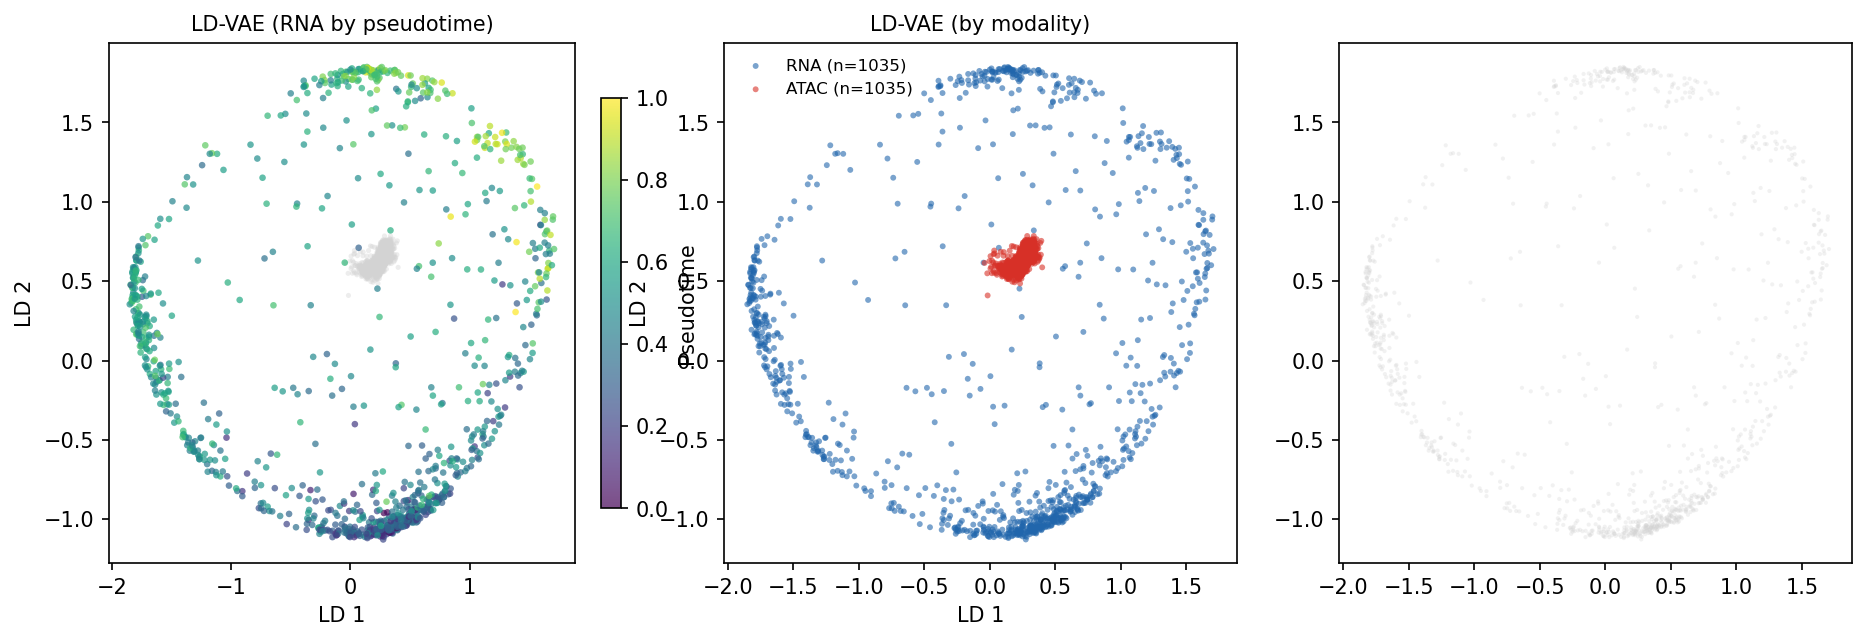

In [18]:
grn.eval(); vel_head.eval(); cell_encoder.eval()
with torch.no_grad():
    z_rna = ld_decoder(cell_encoder.encoder(X_t))[0].cpu().numpy()
    z_atac = ld_decoder(cell_encoder.encoder(torch.tensor(gene_activity, dtype=torch.float32)))[0].cpu().numpy()
    scaler = StandardScaler()
    z_rna_plot  = scaler.fit_transform(z_rna)
    z_atac_plot = scaler.transform(z_atac)
    gl = ld_decoder.get_gene_loadings()
    gl_plot = gl * (2.0 / (np.abs(gl).max() + 1e-8))

plot_ld_embedding(z_rna_plot, pseudo_norm, gl_plot, A_genes,
                  z_2d_atac=z_atac_plot, highlight_genes=MARKER_GENES,
                  save_path=f"{OUT_DIR}/ld_embedding_biplot.png")
print(f"RNA z std/dim:  {z_rna.std(0).round(3)}")
print(f"ATAC z std/dim: {z_atac.std(0).round(3)}")

    ---------------------------------------------------------------------------

    AttributeError                            Traceback (most recent call last)

    Cell In[27], line 11
          7     z_atac_plot = scaler.transform(z_atac)
          8     gl = ld_decoder.get_gene_loadings()
          9     gl_plot = gl * (2.0 / (np.abs(gl).max() + 1e-8))
         10 
    ---> 11 plot_ld_embedding(z_rna_plot, pseudo_norm, gl_plot, A_genes,
         12                   z_2d_atac=z_atac_plot, highlight_genes=MARKER_GENES,
         13                   save_path=f"{OUT_DIR}/ld_embedding_biplot.png")
         14 print(f"RNA z std/dim:  {z_rna.std(0).round(3)}")


    Cell In[20], line 63, in plot_ld_embedding(z_2d_rna, pseudo_norm, gene_loadings, A_genes, z_2d_atac, highlight_genes, n_arrow_genes, save_path)
         59         other = [i for i in np.argsort(-mags) if i not in hi]
         60         show = hi + other[:max(0, n_arrow_genes - len(hi))]
         61     else:
         62         show = np.argsort(-mags)[:n_arrow_genes]
    ---> 63     xr = z_2d_rna[:, 0].ptp(); yr = z_2d_rna[:, 1].ptp()
         64     scale = 0.35 * min(xr, yr) / (mags[show].max() + 1e-8)
         65     for idx in show:
         66         dx, dy = gene_loadings[idx] * scale


    AttributeError: 'numpy.ndarray' object has no attribute 'ptp'



    
![png](output_35_1.png)
    

## Step 16: Velocity projection + scVelo-style stream plot (the arrow plot)


In [29]:
V_pred   = np.load(f"{OUT_DIR}/V_pred.npy")
V_proj2d = project_to_2d(V_pred, V_dec2, X, search_space=Z_dec, k=20, scale=1.0,
                          drift_correct=True)

# light neighbor smoothing for a clean field (no pseudotime involved, no masking here
# either — this just averages the SAME learned per-cell vectors over their neighbors,
# it adds no new information)
nn_vis = NearestNeighbors(n_neighbors=31).fit(V_dec2)
_, idx_vis = nn_vis.kneighbors(V_dec2); idx_vis = idx_vis[:, 1:]
V_smooth = 0.7 * V_proj2d + 0.3 * V_proj2d[idx_vis].mean(1)

# ── OPTIONAL diagnostic only, never fed into the arrows ───────────────────────
# A one-line chromatin-breadth check to sanity-check that the inferred low-magnitude
# region actually sits in your expected purple hub. Delete freely — it's not part
# of the pipeline.
# p = local_access / (local_access.sum(1, keepdims=True) + 1e-8)
# breadth = -(p * np.log(p + 1e-12)).sum(1)
# root_guess = V_dec2[np.argsort(-breadth)[:50]].mean(0)
# print(f"Highest-chromatin-breadth cells center near ({root_guess[0]:.2f}, {root_guess[1]:.2f})")

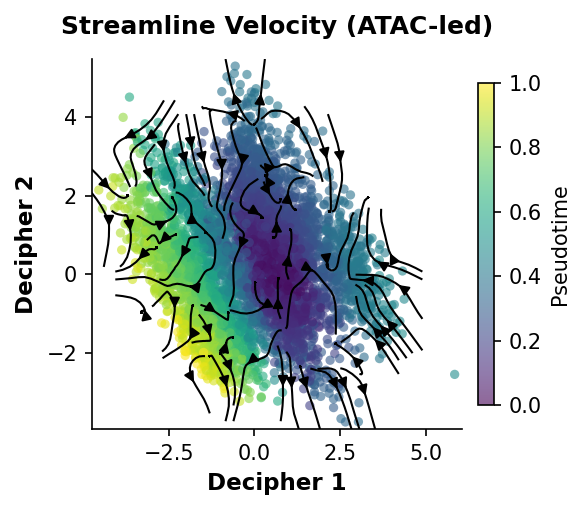

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree
from sklearn.neighbors import NearestNeighbors

fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)
scv = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=pseudo_norm, cmap="viridis",
                  s=20, alpha=0.6, edgecolors='none', rasterized=True)

X_emb, V_emb = V_dec2, V_smooth
grid_n = 120
x_min, x_max = X_emb[:, 0].min(), X_emb[:, 0].max()
y_min, y_max = X_emb[:, 1].min(), X_emb[:, 1].max()

# Define grid padding and uniform line generator
dx, dy = (x_max - x_min) * 0.02, (y_max - y_min) * 0.02

def make_uniform_line(lo, hi, n):
    step = (hi - lo) / (n - 1)
    return lo + step * np.arange(n)

x_line = make_uniform_line(x_min - dx, x_max + dx, grid_n)
y_line = make_uniform_line(y_min - dy, y_max + dy, grid_n)

# Sanity check uniform spacing
assert np.allclose(np.diff(x_line), x_line[1] - x_line[0])
assert np.allclose(np.diff(y_line), y_line[1] - y_line[0])

Xg, Yg = np.meshgrid(x_line, y_line)
gp = np.c_[Xg.ravel(), Yg.ravel()]

sub = np.random.choice(len(X_emb), min(3000, len(X_emb)), replace=False)
_, gi = NearestNeighbors(n_neighbors=20).fit(X_emb[sub]).kneighbors(gp)
Vg = V_emb[sub][gi].mean(1)

nbc = NearestNeighbors(n_neighbors=1).fit(X_emb)
dgrid = nbc.kneighbors(gp)[0].ravel()
thr = np.percentile(dgrid, 40)

# DENSITY-ONLY mask — keep every in-data grid cell, full stop. The hub is low-speed
# by construction (real biology, not missing signal) and must never be masked out
# on that basis.
mask = dgrid < thr
if mask.sum() == 0:
    mask = np.ones(len(gp), dtype=bool)

tree = cKDTree(gp[mask]); _, nn = tree.query(gp, k=1)
U = Vg[mask][nn, 0].reshape(Xg.shape); W = Vg[mask][nn, 1].reshape(Yg.shape)
gm = dgrid < thr
Uf, Wf = U.ravel(), W.ravel(); Uf[~gm] = 0; Wf[~gm] = 0
U = gaussian_filter(Uf.reshape(Xg.shape), 1.2)
W = gaussian_filter(Wf.reshape(Yg.shape), 1.2)

# Pass 1D x_line and y_line to prevent matplotlib grid alignment errors
ax.streamplot(x_line, y_line, U, W, color="black", density=1.6, linewidth=1,
              arrowsize=1, arrowstyle='-|>', minlength=0.2,
              integration_direction='both', zorder=3)

ax.set_xlabel("Decipher 1", fontsize=11, fontweight='bold')
ax.set_ylabel("Decipher 2", fontsize=11, fontweight='bold')
ax.set_title("Streamline Velocity (ATAC-led)", fontsize=12, pad=12, fontweight='bold')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
cbar = plt.colorbar(scv, ax=ax, fraction=0.04, pad=0.04); cbar.set_label("Pseudotime")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/velocity_stream.png", bbox_inches='tight', dpi=150)
plt.show()

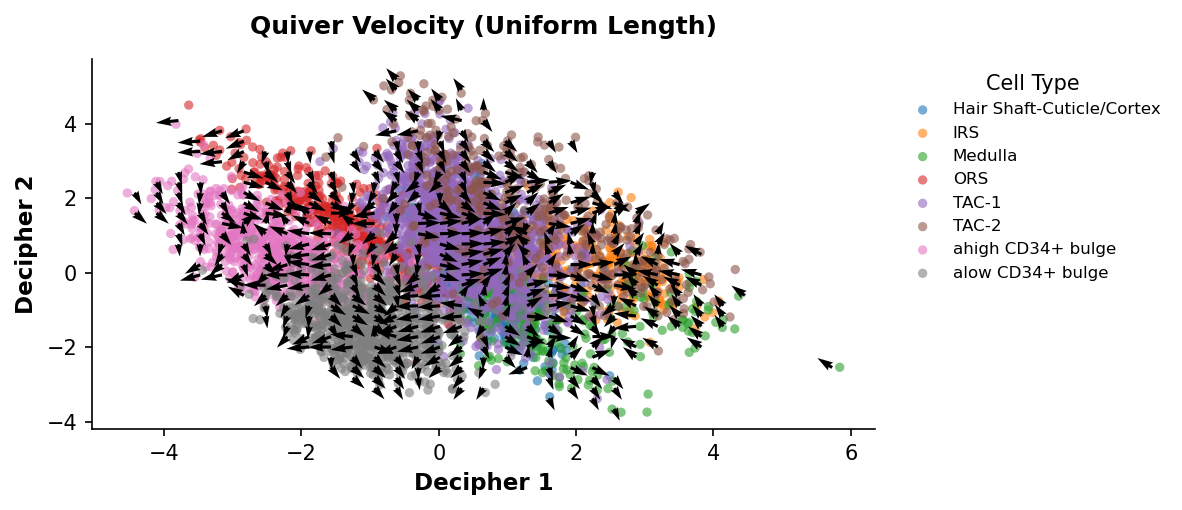

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree
from sklearn.neighbors import NearestNeighbors

fig, ax = plt.subplots(figsize=(8, 3.5), dpi=150)

# 1. Plot categorical cell types
categories = np.unique(cell_types)
cmap = plt.get_cmap("tab10")  # Use "tab20" if >10 cell types

for i, cat in enumerate(categories):
    mask_cat = (cell_types == cat)
    ax.scatter(
        V_dec2[mask_cat, 0], V_dec2[mask_cat, 1],
        color=cmap(i % 10),
        label=str(cat),
        s=20, alpha=0.6, edgecolors='none', rasterized=True
    )

# 2. Vector field processing
X_emb, V_emb = V_dec2, V_smooth
grid_n = 35

x_min, x_max = X_emb[:, 0].min(), X_emb[:, 0].max()
y_min, y_max = X_emb[:, 1].min(), X_emb[:, 1].max()
dx, dy = (x_max - x_min) * 0.02, (y_max - y_min) * 0.02

Xg, Yg = np.meshgrid(np.linspace(x_min - dx, x_max + dx, grid_n),
                     np.linspace(y_min - dy, y_max + dy, grid_n))
gp = np.c_[Xg.ravel(), Yg.ravel()]

sub = np.random.choice(len(X_emb), min(3000, len(X_emb)), replace=False)
_, gi = NearestNeighbors(n_neighbors=20).fit(X_emb[sub]).kneighbors(gp)
Vg = V_emb[sub][gi].mean(1)

nbc = NearestNeighbors(n_neighbors=1).fit(X_emb)
dgrid = nbc.kneighbors(gp)[0].ravel()
thr = np.percentile(dgrid, 40)

mask = dgrid < thr
if mask.sum() == 0:
    mask = np.ones(len(gp), dtype=bool)

tree = cKDTree(gp[mask])
_, nn = tree.query(gp, k=1)
U = Vg[mask][nn, 0].reshape(Xg.shape)
W = Vg[mask][nn, 1].reshape(Yg.shape)

gm = (dgrid < thr).reshape(Xg.shape)
U[~gm] = 0
W[~gm] = 0

U = gaussian_filter(U, 0.8)
W = gaussian_filter(W, 0.8)

# Mask background grid points
X_plot, Y_plot = Xg[gm], Yg[gm]
U_plot, W_plot = U[gm], W[gm]

# 3. NORMALIZE VECTORS TO UNIT LENGTH (Uniform Arrow Lengths)
magnitude = np.hypot(U_plot, W_plot)
with np.errstate(divide='ignore', invalid='ignore'):
    U_norm = np.where(magnitude > 0, U_plot / magnitude, 0)
    W_norm = np.where(magnitude > 0, W_plot / magnitude, 0)

# 4. Draw quiver arrows with uniform length
# Note: Adjust 'scale' (e.g., 20–35) to make the fixed-length arrows longer or shorter
ax.quiver(
    X_plot, Y_plot, U_norm, W_norm,
    color="black",
    angles='xy', scale_units='xy', scale=3,
    width=0.004, headwidth=3, headlength=5,
    zorder=3
)

# 5. Axes styling & legend
ax.set_xlabel("Decipher 1", fontsize=11, fontweight='bold')
ax.set_ylabel("Decipher 2", fontsize=11, fontweight='bold')
ax.set_title("Quiver Velocity (Uniform Length)", fontsize=12, pad=12, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False, title="Cell Type", fontsize=8)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/velocity_quiver_uniform.png", bbox_inches='tight', dpi=150)
plt.show()

![png](output_38_0.png)
    



In [21]:
def assign_velten_celltypes(rna_adata, V_dec2, X_full, gene_to_idx_full):
    """
    Velten 2017 cell type assignment via FACS gates + marker gene rescue.
    Returns cell_types (N,) array of string labels.
    """
    obs = rna_adata.obs.copy()
    N   = len(obs)

    # ── Marker gene scoring ──────────────────────────────────────────────────
    MARKER_GENES = {
        'HSC': ['CD34', 'THY1', 'PROM1', 'ITGA6'],
        'MPP': ['CD34', 'FLT3', 'GATA2'],
        'MLP': ['CD34', 'IL7R', 'FLT3', 'DNTT'],
        'CMP': ['CD34', 'FLT3', 'CSF1R', 'CEBPA'],
        'MEP': ['GATA1', 'GATA2', 'KLF1', 'EPOR', 'GYPA'],
        'GMP': ['MPO', 'ELANE', 'SPI1', 'LYZ', 'CEBPA'],
    }
    scores = {}
    for ct, markers in MARKER_GENES.items():
        s = np.zeros(N, dtype=np.float32)
        n_found = 0
        for gene in markers:
            if gene in gene_to_idx_full:
                expr   = X_full[:, gene_to_idx_full[gene]].astype(np.float32)
                expr_z = (np.log1p(expr) - np.log1p(expr).mean()) / (np.log1p(expr).std() + 1e-8)
                s += expr_z; n_found += 1
        scores[ct] = s / n_found if n_found > 0 else s
    score_df = pd.DataFrame(scores)

    # ── FACS gates — calibrated thresholds ──────────────────────────────────
    def q_gate(col, pct, above=True):
        if col not in obs.columns: return np.zeros(N, dtype=bool)
        thresh = obs[col].quantile(pct / 100)
        return (obs[col] > thresh) if above else (obs[col] <= thresh)

    lin_neg    = q_gate('facs_lin',    30, False)
    cd34_pos   = q_gate('facs_cd34',   40, True)
    cd38_lo    = q_gate('facs_cd38',   33, False)
    cd38_hi    = q_gate('facs_cd38',   50, True)
    cd90_pos   = q_gate('facs_cd90',   50, True)
    cd135_pos  = q_gate('facs_cd135',  40, True)
    cd135_neg  = q_gate('facs_cd135',  40, False)
    cd45ra_pos = q_gate('facs_cd45ra', 50, True)
    cd45ra_neg = q_gate('facs_cd45ra', 50, False)

    cell_types = np.full(N, 'CLOUD', dtype=object)
    base = lin_neg & cd34_pos
    cell_types[base & cd38_hi & cd45ra_pos]                     = 'GMP'
    cell_types[base & cd38_hi & cd135_neg & cd45ra_neg]         = 'MEP'
    cell_types[base & cd38_hi & cd135_pos & cd45ra_neg]         = 'CMP'
    cell_types[base & cd38_lo & cd45ra_pos]                     = 'MLP'
    cell_types[base & cd38_lo & ~cd90_pos & cd45ra_neg]         = 'MPP'
    cell_types[base & cd38_lo & cd90_pos  & cd45ra_neg]         = 'HSC'

    # ── Marker rescue for remaining CLOUD cells ──────────────────────────────
    SCORE_THRESHOLD = 0.5
    cloud_idx  = np.where(cell_types == 'CLOUD')[0]
    best_ct    = score_df.values[cloud_idx].argmax(axis=1)
    best_score = score_df.values[cloud_idx].max(axis=1)
    ct_names   = list(score_df.columns)
    for ci, bct, bsc in zip(cloud_idx, best_ct, best_score):
        if bsc > SCORE_THRESHOLD:
            cell_types[ci] = ct_names[bct]

    print("Cell type counts (FACS gates + marker rescue):")
    unique, counts = np.unique(cell_types, return_counts=True)
    for u, c in sorted(zip(unique, counts), key=lambda x: -x[1]):
        print(f"  {u:<8}: {c}")
        
    return cell_types


cell_types = assign_velten_celltypes(rna_adata, V_dec2, X_full, gene_to_idx_full)
rna_adata.obs['velten_gate_celltype'] = cell_types


Cell type counts (FACS gates + marker rescue):
  CLOUD   : 246
  MEP     : 213
  GMP     : 198
  MPP     : 139
  HSC     : 127
  MLP     : 75
  CMP     : 37


    Cell type counts (FACS gates + marker rescue):
      CLOUD   : 246
      MEP     : 213
      GMP     : 198
      MPP     : 139
      HSC     : 127
      MLP     : 75
      CMP     : 37



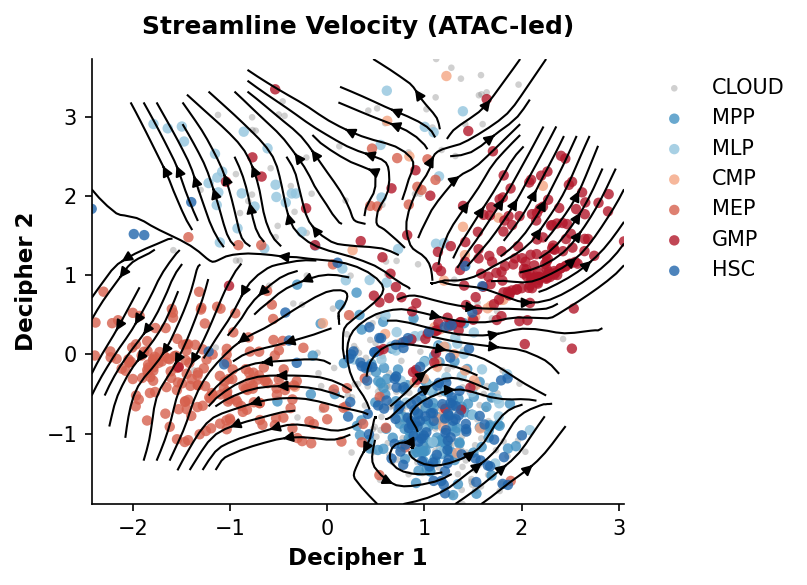

In [22]:
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Widen slightly to accommodate the legend
fig, ax = plt.subplots(figsize=(5.5, 4), dpi=150)

# Cell type palette and plotting
palette = {
    'HSC': '#2166AC', 'MPP': '#4393C3', 'MLP': '#92C5DE',
    'CMP': '#F4A582', 'MEP': '#D6604D', 'GMP': '#B2182B', 
    'CLOUD': '#666565'
}

for ct in ['CLOUD', 'MPP', 'MLP', 'CMP', 'MEP', 'GMP', 'HSC']:
    mask = (cell_types == ct)
    if not mask.any(): continue
    ax.scatter(V_dec2[mask, 0], V_dec2[mask, 1],
               c=palette.get(ct, '#999999'), 
               s=10 if ct == 'CLOUD' else 25,
               alpha=0.3 if ct == 'CLOUD' else 0.8,
               label=ct, edgecolors='none', rasterized=True)

# Streamline computation
X_emb, V_emb = V_dec2, V_smooth
grid_n = 120
x_min, x_max = X_emb[:, 0].min(), X_emb[:, 0].max()
y_min, y_max = X_emb[:, 1].min(), X_emb[:, 1].max()
Xg, Yg = np.meshgrid(np.linspace(x_min, x_max, grid_n),
                     np.linspace(y_min, y_max, grid_n))
gp = np.c_[Xg.ravel(), Yg.ravel()]

sub = np.random.choice(len(X_emb), min(3000, len(X_emb)), replace=False)
_, gi = NearestNeighbors(n_neighbors=20).fit(X_emb[sub]).kneighbors(gp)
Vg = V_emb[sub][gi].mean(1)

nbc = NearestNeighbors(n_neighbors=1).fit(X_emb)
dgrid = nbc.kneighbors(gp)[0].ravel()
thr = np.percentile(dgrid, 40)
# DENSITY-ONLY mask
mask = dgrid < thr
if mask.sum() == 0:
    mask = np.ones(len(gp), dtype=bool)

tree = cKDTree(gp[mask]); _, nn = tree.query(gp, k=1)
U = Vg[mask][nn, 0].reshape(Xg.shape); W = Vg[mask][nn, 1].reshape(Yg.shape)
gm = dgrid < thr
Uf, Wf = U.ravel(), W.ravel(); Uf[~gm] = 0; Wf[~gm] = 0
U = gaussian_filter(Uf.reshape(Xg.shape), 1.2)
W = gaussian_filter(Wf.reshape(Yg.shape), 1.2)

ax.streamplot(Xg, Yg, U, W, color="black", density=1.4, linewidth=1,
              arrowsize=1, arrowstyle='-|>', minlength=0.2,
              integration_direction='both', zorder=3)

ax.set_xlabel("Decipher 1", fontsize=11, fontweight='bold')
ax.set_ylabel("Decipher 2", fontsize=11, fontweight='bold')
ax.set_title("Streamline Velocity (ATAC-led)", fontsize=12, pad=12, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Replaced colorbar with legend outside the plot
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False, fontsize=10)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/velocity_stream_celltypes.png", bbox_inches='tight', dpi=150)
plt.show()

![png](output_40_0.png)
    



In [ ]:
V_pred   = np.load(f"{OUT_DIR}/V_pred.npy")

# k and scale both loosen the transition kernel used to project into 2D:
# - k raised 20 -> 45 so a hub cell's neighbor set has a real chance of including
#   early-committing cells from ALL emerging branches, not just whichever branch
#   happens to be locally over-represented in a small neighborhood.
# - scale lowered 1.0 -> 0.4 so the softmax over cosine similarities doesn't
#   collapse almost all its weight onto a single best-matching neighbor — a hard
#   winner-take-all kernel is exactly what produces "points toward one branch
#   only" even when the underlying G-dim vector has real (if weaker) signal
#   toward the other branches too.
V_proj2d = project_to_2d(V_pred, V_dec2, X, search_space=Z_dec, k=45, scale=0.4,
                          drift_correct=True)

# NOTE: the old post-hoc 2D blend (`0.7*V_proj2d + 0.3*mean(31 neighbors)`) has
# been removed. It was a flat, unweighted neighbor-mean applied directly to the
# plotted arrows — the same "averaging destroys branches" failure mode already
# fixed at the training level (Step 10), just reintroduced one step later, in 2D.
# At a genuine bifurcation, that kind of blend pulls each arrow toward the mean
# of neighbors that are, by construction, headed in different directions.
# project_to_2d's own kernel is already the correct smoothing for this step (it's
# the same cosine-weighted transition-probability construction scVelo uses for
# its grid/stream visualizations); no further blending belongs on top of it.
V_smooth = V_proj2d

# ── OPTIONAL diagnostic only, never fed into the arrows ───────────────────────
# A one-line chromatin-breadth check to sanity-check that the inferred low-magnitude
# region actually sits in your expected purple hub. Delete freely — it's not part
# of the pipeline.
# p = local_access / (local_access.sum(1, keepdims=True) + 1e-8)
# breadth = -(p * np.log(p + 1e-12)).sum(1)
# root_guess = V_dec2[np.argsort(-breadth)[:50]].mean(0)
# print(f"Highest-chromatin-breadth cells center near ({root_guess[0]:.2f}, {root_guess[1]:.2f})")

from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree


fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)
scv = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=pseudo_norm, cmap="viridis",
                 s=20, alpha=0.6, edgecolors='none', rasterized=True)


X_emb, V_emb = V_dec2, V_smooth
grid_n = 120
x_min, x_max = X_emb[:, 0].min(), X_emb[:, 0].max()
y_min, y_max = X_emb[:, 1].min(), X_emb[:, 1].max()
Xg, Yg = np.meshgrid(np.linspace(x_min, x_max, grid_n),
                     np.linspace(y_min, y_max, grid_n))
gp = np.c_[Xg.ravel(), Yg.ravel()]


sub = np.random.choice(len(X_emb), min(3000, len(X_emb)), replace=False)
_, gi = NearestNeighbors(n_neighbors=20).fit(X_emb[sub]).kneighbors(gp)
Vg = V_emb[sub][gi].mean(1)


nbc = NearestNeighbors(n_neighbors=1).fit(X_emb)
dgrid = nbc.kneighbors(gp)[0].ravel()
# Threshold raised 40th -> 65th percentile. The old 40th-percentile cutoff was
# discarding grid points in the genuinely sparser (but real) connective regions
# between clusters -- exactly the "between-cluster gap" where arrows were
# vanishing. This still excludes truly empty space, it just stops treating
# low-density-but-real transitional cells as missing data.
thr = np.percentile(dgrid, 65)
# DENSITY-ONLY mask — keep every in-data grid cell under the (now looser)
# threshold, full stop. The hub is low-speed by construction (real biology, not
# missing signal) and must never be masked out on that basis.
mask = dgrid < thr
if mask.sum() == 0:
   mask = np.ones(len(gp), dtype=bool)


tree = cKDTree(gp[mask]); _, nn = tree.query(gp, k=1)
U = Vg[mask][nn, 0].reshape(Xg.shape); W = Vg[mask][nn, 1].reshape(Yg.shape)
gm = dgrid < thr
Uf, Wf = U.ravel(), W.ravel(); Uf[~gm] = 0; Wf[~gm] = 0
U = gaussian_filter(Uf.reshape(Xg.shape), 1.2)
W = gaussian_filter(Wf.reshape(Yg.shape), 1.2)


ax.streamplot(Xg, Yg, U, W, color="black", density=1.4, linewidth=1,
             arrowsize=1, arrowstyle='-|>', minlength=0.2,
             integration_direction='both', zorder=3)
ax.set_xlabel("Decipher 1", fontsize=11, fontweight='bold')
ax.set_ylabel("Decipher 2", fontsize=11, fontweight='bold')
ax.set_title("Streamline Velocity (ATAC-led)", fontsize=12, pad=12, fontweight='bold')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
cbar = plt.colorbar(scv, ax=ax, fraction=0.04, pad=0.04); cbar.set_label("Pseudotime")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/velocity_stream.png", bbox_inches='tight', dpi=150)
plt.show()

![png](output_41_0.png)
    

## Step 17: GRN mixing diagnostics (temperature = 1.0)

The per-atom maps below are drawn at the **true inference temperature (1.0)**. Committed
cells (branch tips) should be dark for one atom; transition cells should show intermediate
values across ≥2 atoms.


In [ ]:
grn.eval(); cell_encoder.eval()
with torch.no_grad():
    W_soft = cell_encoder(X_t, temperature=1.0).numpy()      # (N, D) — what we actually use

ent = -(W_soft * np.log(W_soft + 1e-8)).sum(1)
print("Mean mixing weight/atom:", W_soft.mean(0).round(3))
print("Std  mixing weight/atom:", W_soft.std(0).round(3))
print(f"Mean entropy: {ent.mean():.3f} / {np.log(D_ATOMS):.3f} max "
      f"(want ~0.3-0.7 of max: mixed transitions, committed tips)")
print(f"Fraction of cells that are 'committed' (max weight > 0.8): {(W_soft.max(1) > 0.8).mean():.1%}")

fig, axes = plt.subplots(2, (D_ATOMS + 1) // 2, figsize=(5 * ((D_ATOMS + 1) // 2), 8))
axes = np.atleast_1d(axes).flatten()
for d in range(D_ATOMS):
    ax = axes[d]
    scv = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=W_soft[:, d], cmap='YlOrRd',
                     s=8, alpha=0.8, vmin=0, vmax=1)
    plt.colorbar(scv, ax=ax, fraction=0.04)
    A_atom = grn.A_dict[d].detach().cpu().numpy()
    top_tf = A_tfs[np.abs(A_atom).sum(0).argmax()]
    ax.set_title(f"Atom {d}  (top TF: {top_tf})", fontsize=9)
    ax.set_xlabel("Decipher 1"); ax.set_ylabel("Decipher 2")
for j in range(D_ATOMS, len(axes)):
    axes[j].axis('off')
plt.suptitle("Per-cell GRN mixing weights (T=1.0)", fontsize=11)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/atom_weights_spatial.png", dpi=150, bbox_inches='tight')
plt.show()

    Mean mixing weight/atom: [0.082 0.332 0.231 0.355]
    Std  mixing weight/atom: [0.106 0.176 0.113 0.137]
    Mean entropy: 1.124 / 1.386 max (want ~0.3-0.7 of max: mixed transitions, committed tips)
    Fraction of cells that are 'committed' (max weight > 0.8): 0.0%



![png](output_43_1.png)
    



In [ ]:
# entropy map: high in transition regions, low at committed tips (the desired pattern)
fig, ax = plt.subplots(figsize=(4.5, 3.8), dpi=150)
scv = ax.scatter(V_dec2[:, 0], V_dec2[:, 1], c=ent, cmap='magma', s=10, alpha=0.85)
plt.colorbar(scv, ax=ax, fraction=0.04, label='mixing entropy')
ax.set_title("GRN mixing entropy\n(high = transition, low = committed)", fontsize=10)
ax.set_xlabel("Decipher 1"); ax.set_ylabel("Decipher 2")
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/mixing_entropy.png", dpi=150, bbox_inches='tight')
plt.show()

![png](output_44_0.png)
    

## Step 18: Downstream helpers + marker expression


In [ ]:
def top_tf_targets(A_learned, A_tfs, A_genes, tf_name, n=20):
    if tf_name not in A_tfs:
        raise ValueError(f"{tf_name} not in A_tfs")
    t = np.where(A_tfs == tf_name)[0][0]
    col = A_learned[:, t]
    top = np.argsort(-np.abs(col))[:n]
    return [(A_genes[i], float(col[i])) for i in top]

A_learned = np.load(f"{OUT_DIR}/A_learned.npy")
frac_pos = float(np.mean(V_pred.mean(1) > 0))
print(f"Cells with net positive velocity: {frac_pos:.1%}")
print(f"\nTop 10 targets of {A_tfs[0]}:")
for g, w in top_tf_targets(A_learned, A_tfs, A_genes, A_tfs[0], n=10):
    print(f"  {g:20s} weight={w:+.4f}")

    Cells with net positive velocity: 19.1%
    
    Top 10 targets of IRF2:
      CD74                 weight=+0.0816
      C6orf62              weight=+0.0816
      H3F3B                weight=+0.0810
      ACTB                 weight=+0.0795
      FTH1                 weight=+0.0790
      RAB4B-EGLN2          weight=+0.0782
      IDH2                 weight=+0.0728
      UBC                  weight=+0.0705
      HSPA5                weight=+0.0698
      RCN2                 weight=+0.0698




In [ ]:
# continuous marker expression across Decipher space (sanity check for lineages)
plot_genes = [g for g in MARKER_GENES + ['GATA2', 'LMO2'] if g in rna_adata.var_names]
sc.pl.embedding(rna_adata, basis=DECIPHER_BASIS, color=plot_genes, cmap='Reds',
                frameon=False, ncols=3, wspace=0.25, hspace=0.25, show=True)

    ---------------------------------------------------------------------------

    KeyError                                  Traceback (most recent call last)

    Cell In[26], line 3
          1 # continuous marker expression across Decipher space (sanity check for lineages)
          2 plot_genes = [g for g in MARKER_GENES + ['GATA2', 'LMO2'] if g in rna_adata.var_names]
    ----> 3 sc.pl.embedding(rna_adata, basis=DECIPHER_BASIS, color=plot_genes, cmap='Reds',
          4                 frameon=False, ncols=3, wspace=0.25, hspace=0.25, show=True)


    File ~/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/scanpy/plotting/_tools/scatterplots.py:133, in embedding(adata, basis, color, mask_obs, gene_symbols, use_raw, sort_order, edges, edges_width, edges_color, neighbors_key, arrows, arrows_kwds, groups, components, dimensions, layer, projection, scale_factor, color_map, cmap, palette, na_color, na_in_legend, size, frameon, legend_fontsize, legend_fontweight, legend_loc, legend_fontoutline, colorbar_loc, vmax, vmin, vcenter, norm, add_outline, outline_width, outline_color, ncols, hspace, wspace, title, show, ax, return_fig, marker, save, **kwargs)
        130 check_projection(projection)
        131 sanitize_anndata(adata)
    --> 133 basis_values = _get_basis(adata, basis)
        134 dimensions = _components_to_dimensions(
        135     components, dimensions, projection=projection, total_dims=basis_values.shape[1]
        136 )
        137 args_3d = dict(projection="3d") if projection == "3d" else {}


    File ~/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/scanpy/plotting/_tools/scatterplots.py:1200, in _get_basis(adata, basis)
       1198 else:
       1199     msg = f"Could not find {basis!r} or 'X_{basis}' in .obsm"
    -> 1200     raise KeyError(msg)


    KeyError: "Could not find 'X_decipher' or 'X_X_decipher' in .obsm"


---

## Appendix A (optional): velocity robustness across runs

Requires `NUM_RUNS > 1`. Compares 2D arrow direction agreement across runs.


In [ ]:
import seaborn as sns
from scipy.stats import spearmanr

def velocity_robustness_analysis(run_vpreds, pseudo_norm, V_dec2, X, save_path):
    N_runs = len(run_vpreds)
    v2d = [project_to_2d(vp, V_dec2, X, k=20, scale=1.0) for vp in run_vpreds]

    cos_mat = np.zeros((N_runs, N_runs))
    for i in range(N_runs):
        for j in range(N_runs):
            a, b = v2d[i], v2d[j]
            na = np.linalg.norm(a, axis=1, keepdims=True) + 1e-8
            nb = np.linalg.norm(b, axis=1, keepdims=True) + 1e-8
            cos_mat[i, j] = float(((a / na) * (b / nb)).sum(1).mean())

    angles = np.array([np.arctan2(v[:, 1], v[:, 0]) for v in v2d])
    R = np.sqrt(np.sin(angles).mean(0) ** 2 + np.cos(angles).mean(0) ** 2)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=150)
    sns.heatmap(cos_mat, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, ax=axes[0],
                xticklabels=[f"R{i}" for i in range(N_runs)],
                yticklabels=[f"R{i}" for i in range(N_runs)])
    axes[0].set_title("2D direction agreement (cosine)")
    scv = axes[1].scatter(V_dec2[:, 0], V_dec2[:, 1], c=R, cmap='RdYlGn',
                          vmin=0, vmax=1, s=8, alpha=0.8)
    plt.colorbar(scv, ax=axes[1], fraction=0.04, label='consistency R')
    axes[1].set_title("Per-cell arrow consistency")
    off = cos_mat[~np.eye(N_runs, dtype=bool)]
    axes[2].axis('off')
    axes[2].text(0.05, 0.9,
                 f"runs: {N_runs}\nmean off-diag cosine: {off.mean():.3f}\n"
                 f"min cosine: {off.min():.3f}\nmean R: {R.mean():.3f}\n"
                 f"% cells R>0.7: {(R>0.7).mean():.1%}",
                 transform=axes[2].transAxes, va='top', family='monospace',
                 bbox=dict(boxstyle='round', facecolor='lightyellow'))
    for a in axes[:2]:
        a.spines['top'].set_visible(False); a.spines['right'].set_visible(False)
    plt.tight_layout(); plt.savefig(save_path, bbox_inches='tight', dpi=150); plt.show()
    return {"mean_cosine": float(off.mean()), "mean_R": float(R.mean())}

if NUM_RUNS > 1:
    run_vpreds = [np.load(os.path.join(OUT_DIR, f"run{i}", "V_pred.npy")) for i in range(NUM_RUNS)]
    res = velocity_robustness_analysis(run_vpreds, pseudo_norm, V_dec2, X,
                                       save_path=f"{OUT_DIR}/velocity_robustness.png")
    print(res)

## Appendix B (optional): CellOracle GRN comparison

Runs only if `CELLORACLE_A` exists. Compares the learned population GRN (`A_learned`,
gene × TF) against a CellOracle matrix on their shared subspace via per-TF Spearman.


In [ ]:
if os.path.exists(CELLORACLE_A):
    from scipy.stats import spearmanr
    co = np.load(CELLORACLE_A)                       # expected (n_genes, n_tfs) or transpose
    A_ours = np.load(f"{OUT_DIR}/A_learned.npy")     # (G, T)
    if co.shape == A_ours.T.shape:
        co = co.T
    if co.shape == A_ours.shape:
        per_tf = []
        for t in range(A_ours.shape[1]):
            a, b = A_ours[:, t], co[:, t]
            support = (np.abs(a) + np.abs(b)) > 0
            if support.sum() > 5:
                rho, _ = spearmanr(a[support], b[support])
                per_tf.append(rho)
        per_tf = np.array([r for r in per_tf if np.isfinite(r)])
        print(f"Per-TF Spearman vs CellOracle: mean={per_tf.mean():.3f} (n={len(per_tf)} TFs)")
        plt.figure(figsize=(5, 3.5), dpi=150)
        plt.hist(per_tf, bins=25, color='#4C72B0', alpha=0.85)
        plt.axvline(per_tf.mean(), color='red', ls='--', label=f"mean {per_tf.mean():.2f}")
        plt.xlabel("per-TF Spearman"); plt.ylabel("count"); plt.legend()
        plt.title("GRN agreement vs CellOracle"); plt.tight_layout(); plt.show()
    else:
        print(f"Shape mismatch: ours {A_ours.shape} vs CellOracle {co.shape}; align manually.")
else:
    print(f"No CellOracle file at {CELLORACLE_A} — skipping comparison.")

    Shape mismatch: ours (3016, 277) vs CellOracle (11483, 277); align manually.

